# Inference and control: latency, System 1 / System 2, and the control stack ⏱️
### Where a VLA's time goes, how GR00T splits fast and slow, and what classical control still does

**Code:** `src/Halo_VLA/vla_foundations/control.py` (`DualRateRunner`, `PlantRunner`), `thinking.py` (`ThinkingPolicy`), `open_vlas/groot.py` (`GR00TPolicy`) ·
**papers/reports:** GR00T N1 ([arXiv:2503.14734](https://arxiv.org/abs/2503.14734)), π0 ([2410.24164](https://arxiv.org/abs/2410.24164)), OpenVLA ([2406.09246](https://arxiv.org/abs/2406.09246)), RT-2 ([2307.15818](https://arxiv.org/abs/2307.15818)), SmolVLA ([2506.01844](https://arxiv.org/abs/2506.01844)), Gemini Robotics 1.5 (Google DeepMind, 2025).

A robot has to act at tens to hundreds of Hz; a billion-parameter VLM answers in tens to hundreds of milliseconds. This notebook is about the architecture that reconciles the two, in four parts:

| part | question | experiment |
|---|---|---|
| 1 | where does the time of one VLA call go? what *action rate* does it buy? | timing of the VLM, of the action network, and the rate arithmetic |
| 2 | **System 2 / System 1** (GR00T N1): how slowly can the VLM run? | refresh the VLM every `m` ticks while the action network runs at every tick, with a target that moves |
| 3 | **Hierarchical control**: what does the classical controller below the VLA do? | the same chunks sent to a lightly damped servo, directly or through a damping tracker |
| 4 | **Embodied thinking** (Gemini Robotics 1.5): does reasoning before acting help? | a policy that writes its reasoning trace before its action tokens |

### Where this notebook corrects the usual summary
* **GR00T N1's System 1 is not "an MLP head".** System 2 is the VLM (NVIDIA Eagle-2) running at ≈ 10 Hz; **System 1 is a flow-matching Diffusion Transformer** that cross-attends to System 2's features and generates action chunks of 16 at ≈ 120 Hz. (The embodiment-specific *MLPs* are the input/output adapters around the DiT.) System 2 interprets the scene and the instruction; it does **not** produce multi-step plans.
* **Hz numbers are not comparable across papers.** A *query rate* (model calls per second) is not an *action rate* (actions per second): with chunks, `action rate = actions executed per call × query rate`. π0 quotes ≈ 73 ms per chunk on an RTX 4090 (a 50-step chunk executed at 50 Hz); OpenVLA ≈ 6 Hz on a 4090 *with one action per call*; RT-2-PaLI-X 5B ≈ 5 Hz and 55B 1-3 Hz on cloud TPUs. They differ in model size, hardware, camera count and chunking, so ranking "autoregressive 5 Hz < flow matching 10-15 Hz < diffusion 40+ Hz" as properties of the *method* is wrong: it is a property of each system.
* **VLAs sit above, not instead of, the low-level controller.** The VLA outputs end-effector deltas or joint targets at ~5-50 Hz; an impedance / PD controller running at hundreds of Hz to kHz turns them into torques (Part 3).

| | published | this notebook |
|---|---|---|
| System 2 | Eagle-2 VLM, ≈ 10 Hz | toy VLM (4 layers) |
| System 1 | flow-matching DiT, chunk 16, 4 steps, ≈ 120 Hz | DiT with 4 blocks, chunk 16, 4 Euler steps |
| low-level control | impedance control at ≥ 1 kHz | a spring-damper servo, 20 micro-steps per tick |

## Step 0: Setup

We train a GR00T-style policy (frozen VLM features → flow-matching DiT, 4 Euler steps) on the point-world `go to <colour>` task. Its two halves are what Part 1 times and Part 2 runs at different rates.

In [1]:
import copy, time, math, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, ToyVLM, VLMConfig, VLMPretrainer, make_embodied_scenarios, make_reach_demos)
from open_vlas.groot import GR00TConfig, GR00TPolicy
from pi_family import PiTrainer, PiVocabulary
from pi_family.toy import DemoGenerator, PointWorld
from vla_foundations.control import DualRateRunner, PlantRunner, timed

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld(); gen = DemoGenerator(world); vocab = PiVocabulary()
vlm = ToyVLM(VLMConfig(), vocab)
pre = VLMPretrainer(vlm, world); pre.fit(1500)
demos = make_reach_demos(gen, 3000, np.random.default_rng(0))
data = EmbodiedMixture([EmbodiedSource(world, demos, EMBODIMENTS["point2d"], chunk_size=16)])
torch.manual_seed(0)
groot = GR00TPolicy(vlm, GR00TConfig.n1_5())
tr = PiTrainer(groot, data, batch_size=64, lr=2e-3, grad_clip=10.0); tr.fit(2500); groot.eval()
scen = make_embodied_scenarios(gen, "point2d", 96, seed=123)
res = EmbodiedEvaluator(world, 16, 8, 50).run(lambda b: groot.sample_actions(b), scen)
print(f"GR00T-style policy trained in {tr.history.seconds:.0f} s; standard closed loop (re-plan every 8 steps): {res.summary()}")

GR00T-style policy trained in 348 s; standard closed loop (re-plan every 8 steps): {'success': 0.958, 'steps': 12.2, 'path': 0.486, 'wrong_first': 0.031}


# Part 1: Where the time goes

## Step 1: Two networks, two costs

A GR00T-style call has two parts: **System 2**, one pass of the VLM over `[image | instruction]` (the expensive one, and it does *not* depend on the noisy actions), and **System 1**, `K` evaluations of the action network on the noisy chunk, each reusing the VLM features. We time each separately on this machine.

System 2 (VLM, one pass): 1.07 ms | System 1 (one DiT evaluation): 1.98 ms → K = 4 steps: 7.90 ms | full call: 8.17 ms


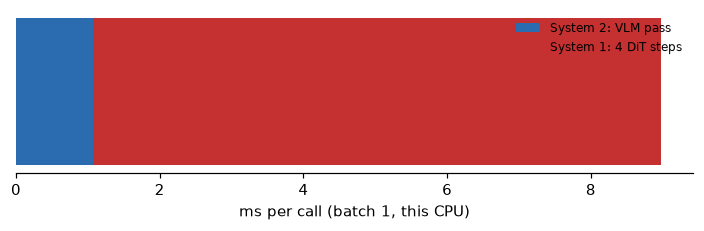

In [2]:
one = data.sample(1, np.random.default_rng(2))
ms_s2 = timed(lambda: groot.encode(one), reps=30)
ctx = groot.encode(one)
state, emb = one.state, one.embodiment
x = torch.randn(1, 16, 4)
ms_s1_step = timed(lambda: groot.velocity(ctx, x, torch.full((1,), 0.5), state, emb), reps=30)
ms_total = timed(lambda: groot.sample_actions(one), reps=20)
print(f"System 2 (VLM, one pass): {ms_s2:.2f} ms | System 1 (one DiT evaluation): {ms_s1_step:.2f} ms → K = 4 steps: {4 * ms_s1_step:.2f} ms | full call: {ms_total:.2f} ms")
fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.barh([0], [ms_s2], color="#2b6cb0", label="System 2: VLM pass"); ax.barh([0], [4 * ms_s1_step], left=[ms_s2], color="#c53030", label="System 1: 4 DiT steps")
ax.set_yticks([]); ax.set_xlabel("ms per call (batch 1, this CPU)"); ax.legend(fontsize=8, frameon=False, loc="upper right"); ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout(); plt.show()

## Step 2: Query rate and action rate

If one call takes `t` seconds and the robot executes `k` of the `H` actions before querying again, then
$$\text{query rate} = \frac1t,\qquad \text{action rate} = \frac{k}{t}\quad(\text{capped by the robot's own control rate}).$$
Two levers raise the action rate: **more actions per call** (chunking: raise `k`), and **cheaper calls** (a smaller VLM, fewer denoising steps, or *not re-running the VLM every call*, Part 2). A third, **asynchronous** inference (compute the next chunk while the current one executes), hides latency instead of reducing it (see the SmolVLA notebook).

In [3]:
rows = [("one action per call (RT-2 / OpenVLA style)", ms_total, 1), ("chunk of 16, execute 8", ms_total, 8), ("chunk of 16, execute 16", ms_total, 16), ("System 1 only (VLM features reused)", 4 * ms_s1_step, 8)]
print(f"{'scheme':45s} {'ms/call':>8s} {'actions/call':>13s} {'query rate':>11s} {'action rate':>12s}")
for name, t, k in rows:
    print(f"{name:45s} {t:8.2f} {k:13d} {1000 / t:9.0f} Hz {1000 * k / t:10.0f} Hz")

scheme                                         ms/call  actions/call  query rate  action rate
one action per call (RT-2 / OpenVLA style)        8.17             1       122 Hz        122 Hz
chunk of 16, execute 8                            8.17             8       122 Hz        979 Hz
chunk of 16, execute 16                           8.17            16       122 Hz       1958 Hz
System 1 only (VLM features reused)               7.90             8       127 Hz       1013 Hz


The last row is the point of the next part: if the VLM does not have to run at every call, the *action* network can run at the fast rate, and the VLM's cost is paid once every `m` calls.

**A caveat about this toy**: here System 1 (4 DiT steps ≈ 8 ms) costs *more* than System 2 (one pass of a 4-layer VLM ≈ 1 ms), the opposite of GR00T or π0, where a multi-billion-parameter VLM dwarfs a ≈ 100M-parameter action network. The logic of the split does not depend on the ratio, but the *saving* does: refreshing a tiny VLM less often saves little time here, while refreshing a 2B VLM at 10 Hz instead of 120 Hz is what makes a humanoid controller feasible.

# Part 2: System 2 / System 1

## Step 3: What happens when System 2 is stale?

GR00T N1 runs the VLM (**System 2**) at ≈ 10 Hz and the DiT (**System 1**) at ≈ 120 Hz: System 1 generates a chunk from the *latest VLM features* and the *current proprioception*. The VLM features go stale between refreshes. Does that matter? Only if the world changes. We make it change: **the target object is moved** at tick 4 (before the robot
could reach it). System 1 keeps running at every tick, but until System 2 looks at the image again it only knows where the object *was*.
`DualRateRunner(s2_period=m)` refreshes the VLM every `m` ticks.

System 2 refreshed every  1 ticks: {'success': 0.938, 'steps': 14.8, 's2_calls': 17.0, 's1_calls': 17.0}


System 2 refreshed every  2 ticks: {'success': 0.958, 'steps': 14.7, 's2_calls': 8.3, 's1_calls': 16.2}


System 2 refreshed every  4 ticks: {'success': 0.979, 'steps': 14.6, 's2_calls': 4.2, 's1_calls': 15.4}


System 2 refreshed every  8 ticks: {'success': 0.969, 'steps': 18.5, 's2_calls': 2.9, 's1_calls': 19.4}


System 2 refreshed every 16 ticks: {'success': 0.906, 'steps': 28.2, 's2_calls': 2.4, 's1_calls': 30.2}


System 2 refreshed every 50 ticks: {'success': 0.0, 'steps': nan, 's2_calls': 1.0, 's1_calls': 50.0}


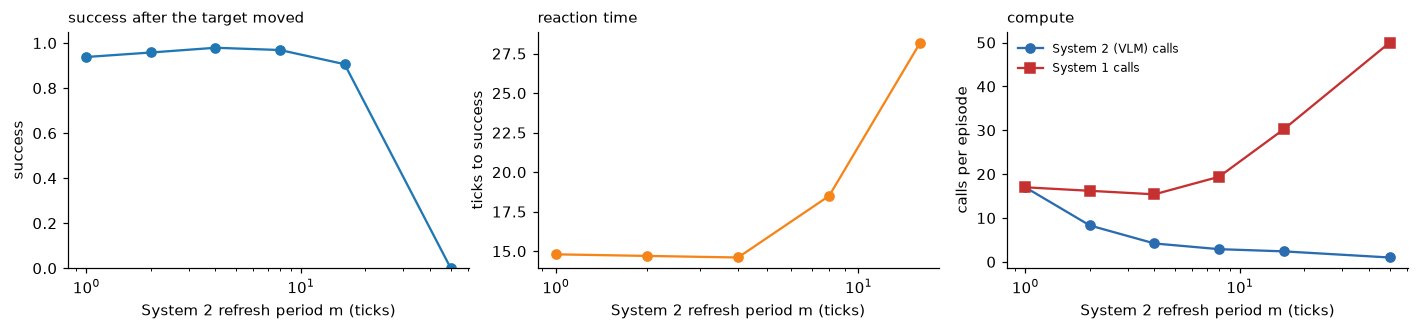

In [4]:
new_positions = DualRateRunner.relocate(scen, seed=5)
periods = [1, 2, 4, 8, 16, 50]
dual = {}
for m in periods:
    dual[m] = DualRateRunner(world, groot, m).run(scen, new_positions).summary()
    print(f"System 2 refreshed every {m:2d} ticks: {dual[m]}", flush=True)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.1))
axes[0].plot(periods, [dual[m]["success"] for m in periods], "o-"); axes[0].set_ylabel("success"); axes[0].set_ylim(0, 1.05); axes[0].set_title("success after the target moved", fontsize=10, loc="left")
axes[1].plot(periods, [dual[m]["steps"] for m in periods], "o-", color="#f58518"); axes[1].set_ylabel("ticks to success"); axes[1].set_title("reaction time", fontsize=10, loc="left")
axes[2].plot(periods, [dual[m]["s2_calls"] for m in periods], "o-", color="#2b6cb0", label="System 2 (VLM) calls"); axes[2].plot(periods, [dual[m]["s1_calls"] for m in periods], "s-", color="#c53030", label="System 1 calls")
axes[2].set_ylabel("calls per episode"); axes[2].legend(fontsize=8, frameon=False); axes[2].set_title("compute", fontsize=10, loc="left")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("System 2 refresh period m (ticks)"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the plots** (one seed, 96 scenes). Up to a refresh period of **8 ticks the success hardly changes** (0.94-0.98) while the number of VLM calls per episode falls from 17 to ≈ 3: System 1 absorbs the fast part of the control, and the VLM is only needed when the *world* changes. The **reaction time** grows with the period (a moved object is noticed late: 14.8 ticks to success at period 1, 18.5 at 8, 28 at 16) and success begins to fall at 16 ticks (0.91);
**never refreshing** (period 50 = the VLM looks once) is a catastrophe (0.00): the robot keeps heading for where the object was. This is the case for the dual-system design: the *rate of the perception loop* should match *how fast the world changes*, not the control rate of the actuators.

(The measurement also shows what GR00T relies on: System 1 reads *fresh proprioception* at every tick, so even with a stale scene it does not drive the arm blindly; it knows where the arm is.)

# Part 3: The control stack below the VLA

## Step 4: A lightly damped servo

A real arm is not a point that moves where it is told. Its servo tracks a position setpoint `c` like a **spring-damper**: $p'' = \omega^2 (c - p) - 2\zeta\omega p'$, with `ζ < 1` it **rings**. A VLA that outputs joint-position *targets* and sends them straight to such a servo (`direct`) gets ringing; if a **classical outer loop**, running many times per VLA tick, injects damping, $c = w - k_d\, p'$ with $k_d = 2(1-\zeta)/\omega$ (`tracked`), the closed loop becomes critically damped for the known plant. The VLA still decides *where* (the waypoints `w`), the classical loop decides *how* to get there.

To isolate the control interface from the policy's own errors we use a **perfect kinematic planner** as the "VLA" (it plans 8 waypoints straight to the target) and disturb the servo with random velocity impulses; a learned policy is an exercise.

In [5]:
def planner(horizon=8):
    # a perfect kinematic chunk planner: the actions that would take a *kinematic* point straight to the target
    def fn(batch):
        out = torch.zeros(batch.size, horizon, 4)
        for i, s in enumerate(scen):
            p, goal = batch.state[i, :2].numpy().copy(), s.scene.objects[s.target]
            for h in range(horizon):
                d = goal - p
                a = d / max(np.linalg.norm(d), 1e-8) * min(0.9, np.linalg.norm(d) / world.max_step)
                out[i, h, :2] = torch.from_numpy(a).float(); p = world.step(p, a)
        return out
    return fn
omega = 2 * math.pi / 6                      # a 6-tick period of oscillation
rows = {}
for kick in (0.0, 0.3, 1.0):
    for zeta in (0.7, 0.3, 0.1):
        for mode in ("direct", "tracked"):
            rows[(kick, zeta, mode)] = PlantRunner(world, omega, zeta, mode, 8, 4, kick=kick, tolerance=0.025).run(planner(), scen).summary()
print(f"{'disturbance':>11s} {'damping ζ':>9s} | {'direct: success / jitter':>26s} | {'tracked: success / jitter':>26s}")
for kick in (0.0, 0.3, 1.0):
    for zeta in (0.7, 0.3, 0.1):
        d, t = rows[(kick, zeta, "direct")], rows[(kick, zeta, "tracked")]
        print(f"{kick:11.1f} {zeta:9.1f} | {d['success']:14.2f} / {d['jitter']:.4f}   | {t['success']:14.2f} / {t['jitter']:.4f}")

disturbance damping ζ |   direct: success / jitter |  tracked: success / jitter
        0.0       0.7 |           1.00 / 0.0000   |           1.00 / 0.0000
        0.0       0.3 |           1.00 / 0.0000   |           1.00 / 0.0000
        0.0       0.1 |           1.00 / 0.0003   |           1.00 / 0.0000
        0.3       0.7 |           1.00 / 0.0087   |           1.00 / 0.0065
        0.3       0.3 |           0.90 / 0.0148   |           1.00 / 0.0065
        0.3       0.1 |           0.45 / 0.0259   |           1.00 / 0.0065
        1.0       0.7 |           0.38 / 0.0291   |           0.49 / 0.0218
        1.0       0.3 |           0.09 / 0.0492   |           0.49 / 0.0218
        1.0       0.1 |           0.01 / 0.0785   |           0.49 / 0.0218


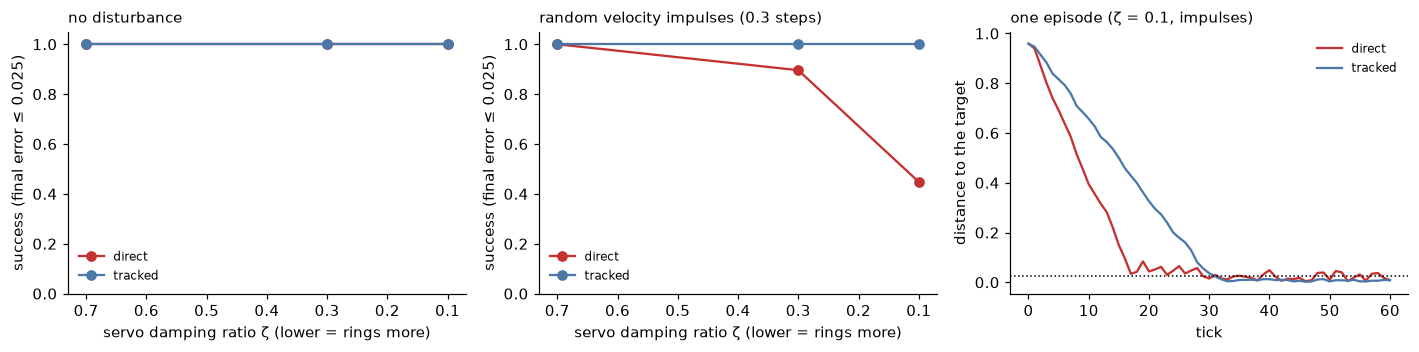

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, (kick, title) in zip(axes[:2], ((0.0, "no disturbance"), (0.3, "random velocity impulses (0.3 steps)"))):
    for mode, col in (("direct", "#c53030"), ("tracked", "#4c78a8")):
        ax.plot([0.7, 0.3, 0.1], [rows[(kick, z, mode)]["success"] for z in (0.7, 0.3, 0.1)], "o-", color=col, label=mode)
    ax.set_xlabel("servo damping ratio ζ (lower = rings more)"); ax.set_ylabel("success (final error ≤ 0.025)"); ax.set_ylim(0, 1.05); ax.set_title(title, fontsize=10, loc="left"); ax.legend(fontsize=8, frameon=False); ax.invert_xaxis()
    ax.spines[["top", "right"]].set_visible(False)
# one episode's distance to the target over time (ζ = 0.1, impulses)
i = 3
for mode, col in (("direct", "#c53030"), ("tracked", "#4c78a8")):
    r = PlantRunner(world, omega, 0.1, mode, 8, 4, kick=0.3, tolerance=0.025).run(planner(), scen)
    goal = scen[i].scene.objects[scen[i].target]
    axes[2].plot(np.linalg.norm(r.trajectories[i] - goal, axis=1), color=col, label=mode)
axes[2].axhline(0.025, color="k", ls=":", lw=1); axes[2].set_xlabel("tick"); axes[2].set_ylabel("distance to the target"); axes[2].set_title("one episode (ζ = 0.1, impulses)", fontsize=10, loc="left"); axes[2].legend(fontsize=8, frameon=False)
axes[2].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the results.** With a well-damped servo (ζ = 0.7) both ways work. As the servo gets more **underdamped** the *direct* path degrades: the arm rings around the target, impulses keep exciting it, and the success under disturbance falls (to 0.90 at ζ = 0.3 and 0.45 at ζ = 0.1 with impulses of 0.3 steps) with high jitter in the last ticks. The **tracked** version, with the same waypoints, is
**insensitive to ζ** (1.00 at all three, with identical jitter: the loop has been re-damped) and keeps its success. With *strong* impulses (1.0 step) nobody succeeds reliably, but the tracked loop still holds 0.49 at every ζ while the direct path falls from 0.38 to 0.01. The right-hand plot shows the price: the *direct* arm arrives first (about tick 17) and then keeps ringing around the tolerance band, while the *tracked* arm arrives later (about tick 30, critical damping is not the fastest) but settles and stays. Note what the VLA did *not* have to do: it never modelled the servo; it just said where to go, one chunk at a time.

## Step 5: Where does the VLA sit, and what stays classical?

```
 language + cameras ──►  VLA  ──► waypoints / end-effector deltas, ~5-50 Hz
                                       │
                         trajectory generation / IK / safety limits   (classical)
                                       │
                         impedance / PD / MPC tracking,  100 Hz - 1 kHz+   (classical)
                                       │
                                  joint torques
```
* the **VLA** supplies what is hard to program: semantics (what to reach, which object), perception in clutter, generalisation to new instructions;
* **classical** control supplies what is hard to learn from a few demonstrations and must be *guaranteed*: high-rate disturbance rejection and stability (this part), kinematic and joint limits, collision / force safety, precise 6-DoF pose when a calibrated perception pipeline is available (see the perception notebook);
* **MPC / trajectory optimisation** sits between them when a smooth, constraint-respecting path is needed: the VLA's chunk can be used as a reference or a warm start.

# Part 4: Embodied thinking

Gemini Robotics 1.5 introduced **embodied thinking**: before emitting actions, the VLA writes a natural-language *reasoning trace* about the scene and the plan ("the red cup is left of the plate, so I will first …"), and then acts conditioned on it. The claimed benefit is on **long-horizon and ambiguous tasks**; the cost is extra decoding.
We test a small version on the one place where reasoning *could* matter in our world: the **relational** instruction `go to left / right / top / bottom` (which object is the extreme one?). `ThinkingPolicy` first writes the positions of the three objects (two number words each, the format of the VLM's own VQA pre-training) and the chosen target, `red 20 40 green 60 30 blue 80 70 go to green`, and then the action tokens. The direct policy (`think=False`) writes only the action tokens. Same VLM, data (3000 demonstrations) and training steps.

In [7]:
from vla_foundations.autoregressive import ARConfig
from vla_foundations.tasks import make_side_demos, make_side_scenarios
from vla_foundations.thinking import ThinkingPolicy, thought_text
vocab_ar = PiVocabulary(fast_size=256)
vlm_ar = ToyVLM(VLMConfig(width=64, depth=4, num_heads=4, head_dim=16), vocab_ar)
pre2 = VLMPretrainer(vlm_ar, world); pre2.fit(1500)
side_demos = make_side_demos(gen, 3000, np.random.default_rng(1))
side_data = EmbodiedMixture([EmbodiedSource(world, side_demos, EMBODIMENTS["point2d"], chunk_size=1)])
side_scen = make_side_scenarios(gen, 96, 321)
ev1 = EmbodiedEvaluator(world, 1, 1, 50)
think_res = {}
for think in (False, True):
    torch.manual_seed(0)
    m = ThinkingPolicy(vlm_ar, ARConfig(chunk_size=1), think=think)
    tr = PiTrainer(m, side_data, batch_size=64, lr=2e-3, grad_clip=10.0)
    curve = []
    for target in (2000, 4000, 6000):
        tr.fit(2000); m.eval()
        curve.append(ev1.run(lambda b: m.sample_actions(b), side_scen).success_rate); m.train()
    m.eval()
    think_res[think] = dict(curve=curve, model=m, seconds=tr.history.seconds)
    print(f"think={think}: success after 2000 / 4000 / 6000 steps = {curve} ({tr.history.seconds:.0f} s)", flush=True)

think=False: success after 2000 / 4000 / 6000 steps = [0.21875, 0.6979166666666666, 0.8229166666666666] (4680 s)


think=True: success after 2000 / 4000 / 6000 steps = [0.19791666666666666, 0.3541666666666667, 0.4791666666666667] (438 s)


the generated trace names the correct target in 100% of the scenes; example: 'red 70 40 green 50 70 blue 20 50 go to red' (truth: red)


success if the trace is replaced by the CORRECT trace (oracle reasoning): 0.50


decoding cost per action: direct 3.7 ms (2 tokens) | thinking 23.2 ms (14 tokens)


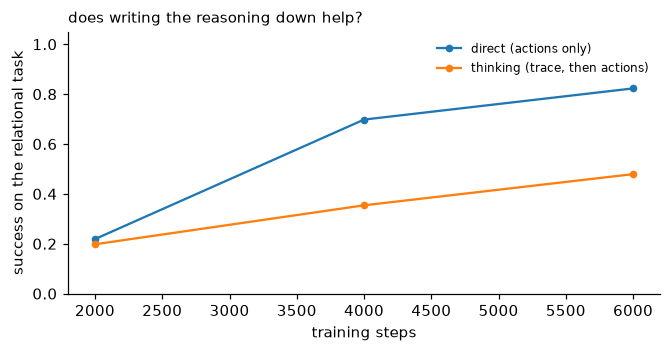

In [8]:
m = think_res[True]["model"]
obs = ev1.observe(side_scen, np.stack([s.scene.robot for s in side_scen])[:, None, :].astype(np.float32), np.full(len(side_scen), -1.0), 0)
m.sample_actions(obs)
right = np.mean([t.split()[-1] == s.target for t, s in zip(m.last_thoughts, side_scen)])
print(f"the generated trace names the correct target in {right:.0%} of the scenes; example: '{m.last_thoughts[0]}' (truth: {side_scen[0].target})")
m.forced_thoughts = [m.vocab.encode(thought_text(s.scene.objects, s.target)) for s in side_scen]
oracle = ev1.run(lambda b: m.sample_actions(b), side_scen).success_rate
m.forced_thoughts = None
print(f"success if the trace is replaced by the CORRECT trace (oracle reasoning): {oracle:.2f}")
one_obs = ev1.observe(side_scen[:1], side_scen[0].scene.robot[None, None, :].astype(np.float32), np.full(1, -1.0), 0)
ms_direct = timed(lambda: think_res[False]["model"].sample_actions(one_obs), reps=10); ms_think = timed(lambda: m.sample_actions(one_obs), reps=10)
print(f"decoding cost per action: direct {ms_direct:.1f} ms (2 tokens) | thinking {ms_think:.1f} ms (14 tokens)")
plots.curves([2000, 4000, 6000], {"direct (actions only)": think_res[False]["curve"], "thinking (trace, then actions)": think_res[True]["curve"]}, "training steps", "success on the relational task", "does writing the reasoning down help?", ylim=(0, 1.05))

**What the measurements say (one seed; this is a toy, and the result is negative).**

* The **reasoning trace is learned perfectly**: it names the correct target in **100 %** of the scenes (it learns to read positions off the image, in the format of the VLM's own VQA pre-training, and to pick the extreme one).
* Yet the **thinking policy is the *worse* controller**: success after 6000 steps is **0.48** against **0.82** for the direct policy, and even with the *correct* trace injected (oracle reasoning) it reaches only 0.50. The bottleneck is the **action stage after the trace**, not the reasoning: conditioning 2 action tokens on 12 tokens of text it wrote itself is a harder mapping to learn than going straight from the image,
  and our toy task is easy enough that the direct policy learns the relational rule implicitly.
* **The cost is immediate**: 14 tokens instead of 2 per action, **23 ms instead of 3.7 ms** to decode.

So in this toy, thinking is a bad trade: the reasoning it adds is something the direct policy can already do. Where Gemini Robotics 1.5 claims a benefit is where the **implicit route fails**: long-horizon, ambiguous or open-world tasks needing knowledge and multi-step reasoning that a reflexive policy cannot compute in one forward pass, and where the *thinking model is a large pre-trained LLM that reasons well to begin with*. The right question is not "does thinking help?" but
"does this task need reasoning the policy cannot do implicitly, and can I afford the latency?". (Note also that the trace can be decoded **asynchronously** at a lower rate than the actions, the same System 2 / System 1 idea as Part 2.)

# Part 5: Recap

**Take-aways.** (1) One VLA call has two costs: the VLM pass (expensive, independent of the actions) and the action network (cheap per step); the **action rate** is `actions per call / call time`, not the query rate. (2) **System 2 / System 1**: refresh the VLM at the rate the *world* changes, run the action network at the rate the *robot* needs: success is flat up to a refresh period of several ticks (≈ 4-8× fewer VLM calls here); never refreshing is fatal.
(3) The VLA outputs *targets*; a **classical high-rate loop** damps and tracks them: it does what a few demonstrations cannot guarantee. (4) **Thinking** before acting is a trade of latency for explicitness (below).

### 🧪 Exercises
1. In Step 3 move the target at tick 12 instead of 4: does a longer refresh period hurt less? (The robot is already closer.)
2. Re-run Step 4 with a **learned** policy instead of the planner (train SmolVLA with `chunk_size = 8`): its imprecision confounds the interface; how do `direct` and `tracked` compare?
3. Give the tracker the *wrong* damping (`zeta` in `PlantRunner` is both the plant's and the tracker's assumption: add a separate `assumed_zeta`): how robust is the design to plant mismatch?
4. Combine Parts 2 and 3: run the dual-rate policy on the servo.